# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

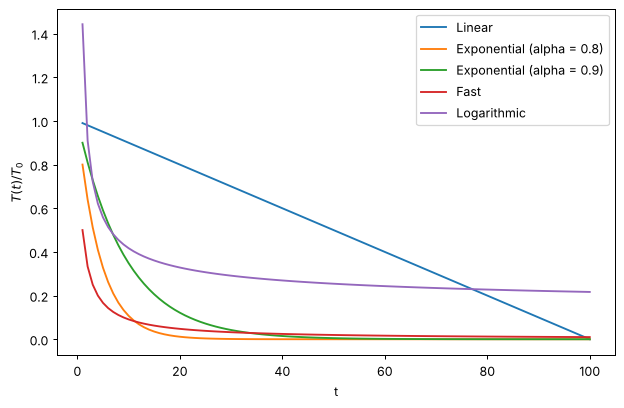

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## Bài 5 – Khảo sát ảnh hưởng của tham số

Để đánh giá một lịch giảm nhiệt ta quan tâm: (1) nhiệt độ giảm nhanh cỡ nào, và (2) *xác suất chấp nhận một bước xấu* $p = e^{-\Delta/T}$ thay đổi ra sao theo thời gian (ví dụ với $\Delta = 1$, tức một bước làm $f$ tăng thêm 1). Nhiệt độ càng cao càng chấp nhận nhiều bước xấu (khám phá), càng thấp càng giống hill climbing (khai thác). Cell dưới thay đổi $\alpha$, $\eta$, $T_0$ rồi vẽ $T(t)$ và $p(t)$.

        Lịch (T0 = 1)  t để T < 0.1  t để T < 0.01
0           Mũ α=0.99           230          459.0
1          Mũ α=0.999          2302         4603.0
2  Tuyến tính η=0.002           450          496.0
3                Fast            10          100.0
4         Logarithmic         22026            NaN

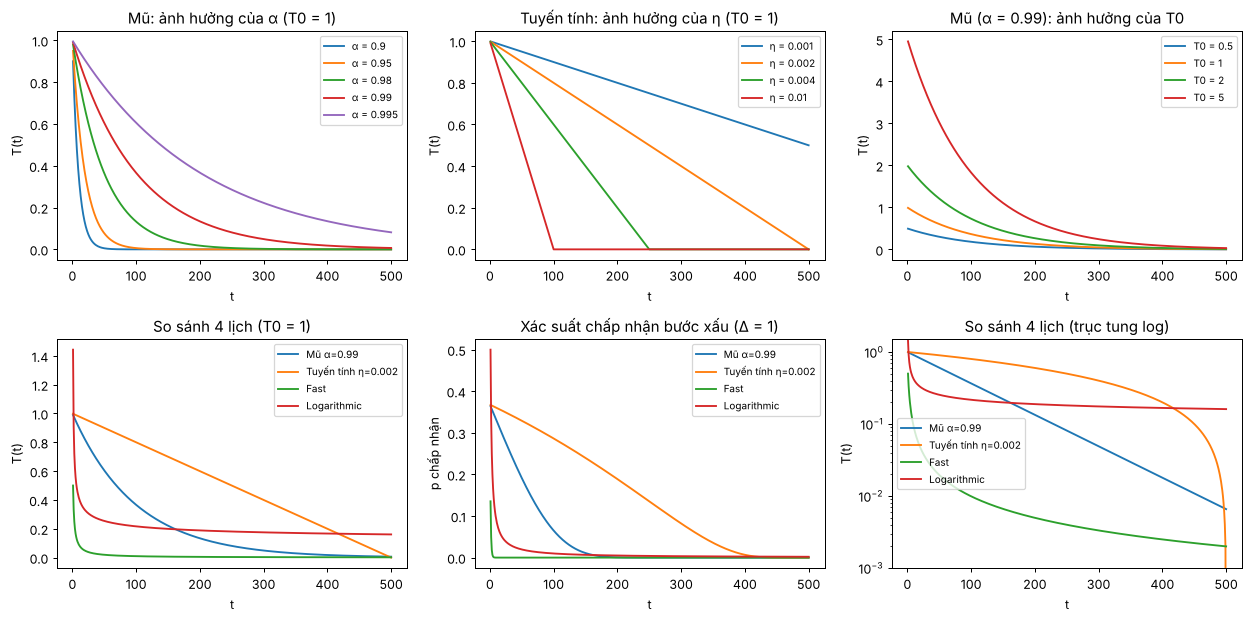

In [7]:
t = np.arange(1, 501)
fig, ax = plt.subplots(2, 3, figsize=(14, 7))

# (a) lịch mũ: thay đổi alpha (T0 = 1)
for a in (0.9, 0.95, 0.98, 0.99, 0.995):
    ax[0, 0].plot(t, temperature_exponential(t, 1, a), label=f"α = {a}")
ax[0, 0].set_title("Mũ: ảnh hưởng của α (T0 = 1)"); ax[0, 0].legend(fontsize=8)

# (b) lịch tuyến tính: thay đổi eta (T0 = 1); nhiệt độ âm được cắt về 0
for eta in (0.001, 0.002, 0.004, 0.01):
    ax[0, 1].plot(t, np.maximum(temperature_linear(t, 1, eta), 0), label=f"η = {eta}")
ax[0, 1].set_title("Tuyến tính: ảnh hưởng của η (T0 = 1)"); ax[0, 1].legend(fontsize=8)

# (c) thay đổi nhiệt độ ban đầu T0 (lịch mũ, α = 0.99)
for T0 in (0.5, 1, 2, 5):
    ax[0, 2].plot(t, temperature_exponential(t, T0, 0.99), label=f"T0 = {T0}")
ax[0, 2].set_title("Mũ (α = 0.99): ảnh hưởng của T0"); ax[0, 2].legend(fontsize=8)

# (d) so sánh 4 lịch cùng T0 = 1
sch = {"Mũ α=0.99": temperature_exponential(t, 1, 0.99), "Tuyến tính η=0.002": np.maximum(temperature_linear(t, 1, 0.002), 0),
       "Fast": temperature_fast(t, 1), "Logarithmic": temperature_logarithmic(t, 1)}
for name, T in sch.items():
    ax[1, 0].plot(t, T, label=name)
ax[1, 0].set_title("So sánh 4 lịch (T0 = 1)"); ax[1, 0].legend(fontsize=8)

# (e) xác suất chấp nhận bước xấu với delta = 1
for name, T in sch.items():
    with np.errstate(divide="ignore", over="ignore"):
        ax[1, 1].plot(t, np.where(T > 0, np.exp(-1.0 / np.maximum(T, 1e-12)), 0), label=name)
ax[1, 1].set_title("Xác suất chấp nhận bước xấu (Δ = 1)"); ax[1, 1].legend(fontsize=8)

# (f) cùng đồ thị nhưng trục tung log để thấy rõ các lịch giảm nhanh/chậm
for name, T in sch.items():
    ax[1, 2].semilogy(t, np.maximum(T, 1e-6), label=name)
ax[1, 2].set_title("So sánh 4 lịch (trục tung log)"); ax[1, 2].set_ylim(1e-3, 1.5); ax[1, 2].legend(fontsize=8)

for a_ in ax.ravel():
    a_.set_xlabel("t"); a_.set_ylabel("T(t)" if a_ not in (ax[1, 1],) else "p chấp nhận")
plt.tight_layout(); plt.show()

# Bảng: sau bao nhiêu bước nhiệt độ rơi xuống dưới 0.1 * T0 và 0.01 * T0
def first_below(T, thr):
    idx = np.flatnonzero(T < thr)
    return int(idx[0] + 1) if len(idx) else None
tt = np.arange(1, 100001)
import pandas as pd
pd.DataFrame({
    "Lịch (T0 = 1)": ["Mũ α=0.99", "Mũ α=0.999", "Tuyến tính η=0.002", "Fast", "Logarithmic"],
    "t để T < 0.1": [first_below(temperature_exponential(tt, 1, 0.99), 0.1), first_below(temperature_exponential(tt, 1, 0.999), 0.1),
                     first_below(temperature_linear(tt, 1, 0.002), 0.1), first_below(temperature_fast(tt, 1), 0.1),
                     first_below(temperature_logarithmic(tt, 1), 0.1)],
    "t để T < 0.01": [first_below(temperature_exponential(tt, 1, 0.99), 0.01), first_below(temperature_exponential(tt, 1, 0.999), 0.01),
                      first_below(temperature_linear(tt, 1, 0.002), 0.01), first_below(temperature_fast(tt, 1), 0.01),
                      first_below(temperature_logarithmic(tt, 1), 0.01)],
})

**Nhận xét.**

* **Lịch mũ:** $\alpha$ càng gần 1 thì nguội càng chậm. Thời gian để $T$ giảm còn 10% là $\ln 0.1/\ln\alpha$ vòng lặp (khoảng 23 vòng với $\alpha=0.9$ nhưng khoảng 230 vòng với $\alpha=0.99$ và 2300 vòng với $\alpha=0.999$). Khi giảm $\alpha$ thuật toán nguội sớm, chuyển sang khai thác và dễ kẹt ở cực trị cục bộ; khi tăng $\alpha$ thuật toán chấp nhận bước xấu lâu hơn nên tìm được nghiệm tốt hơn nhưng chạy lâu hơn.
* **Lịch tuyến tính:** $\eta$ lớn làm nhiệt độ về 0 nhanh (sau $T_0/\eta$ vòng lặp), $\eta$ nhỏ cho lịch nguội chậm. Nhiệt độ giảm *đều* nên thời gian "ấm" (còn khả năng chấp nhận bước xấu) kéo dài tuyến tính và kết thúc đột ngột về 0, nên cần chọn $\eta$ sao cho $T_0/\eta$ bằng số vòng lặp dự định.
* **Lịch fast** ($T_0/(1+t)$) giảm rất nhanh lúc đầu (nhiệt độ giảm một nửa chỉ sau 1 vòng lặp) rồi chỉ còn lại một "đuôi" rất thấp; lịch **logarithmic** ($T_0/\ln(1+t)$) cũng giảm nhanh lúc đầu rồi gần như đi ngang (còn khoảng 0.16 sau 500 vòng và chỉ xuống dưới 0.1 sau khoảng 22 000 vòng): nó duy trì một xác suất chấp nhận bước xấu nhỏ nhưng khác 0 rất lâu, đúng với bảo đảm lý thuyết về hội tụ tới nghiệm tối ưu nhưng trên thực tế quá chậm.
* **Nhiệt độ ban đầu $T_0$** quyết định xác suất chấp nhận bước xấu ngay từ đầu; $T_0$ cao kéo dài giai đoạn khám phá, $T_0$ thấp khiến thuật toán gần như bỏ qua giai đoạn này. $T_0$ nên cùng bậc với độ chênh lệch $\Delta$ điển hình của bài toán.
* **Lịch nào chấp nhận bước xấu lâu nhất?** Theo biểu đồ xác suất chấp nhận ($\Delta = 1$, $T_0 = 1$): trong khoảng 400 vòng đầu lịch tuyến tính giữ xác suất cao nhất rồi tụt đột ngột về 0; lịch mũ $\alpha=0.99$ giảm đều và mượt; lịch fast gần như bằng 0 sau vài chục vòng; lịch logarithmic giảm nhanh lúc đầu nhưng để lại "đuôi" xác suất nhỏ kéo dài. Lịch càng "ấm" lâu thì càng ít bị kẹt nhưng càng tốn thời gian.

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)